# Consistent rates, all ten locations: main's sampler vs the branch sampler

One row per location. For each location three artifacts are compared:

- **main** — built by `main` (PR #82, 250 draws) on 2026-10-23: one NUTS chain, 500 warmup,
  250 consecutive iterations written as the draws, no convergence check
  (`artifact_comparisons/main250/`, see `PROVENANCE.txt` there).
- **refit** — the same inputs refit with this branch's sampler
  (`notebooks/refit_consistent_rates.py` → `artifact_comparisons/refit250/`): knots from
  age 40 with zero rows below, curvature prior on the log S→BBBM hazard, 4 chains, 1000
  warmup, 1250 samples each, convergence gate, thinned to 250 near-independent draws.
- **archive** — the model10.0 artifact used for the published runs (old sampler, 500 draws,
  inputs of January 2026), for reference only.

`consistent_rates_old_vs_new.ipynb` has the same comparison in depth for one location.

In [1]:
import re
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vivarium.artifact import Artifact

from vivarium_csu_alzheimers.data import consistent_rates as cr

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
print(subprocess.run(["date"], capture_output=True, text=True).stdout.strip())

/mnt/share/homes/abie/projects/2026/vivarium_csu_alzheimers/worktrees/consistent-rates-sampler/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mon Oct 26 19:30:30 PDT 2026


## Parameters

In [2]:
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MAIN_DIR = REPO / "artifact_comparisons" / "main250"
REFIT_DIR = REPO / "artifact_comparisons" / "refit250"
ARCHIVE_DIR = Path("/mnt/share/homes/abie/projects/2025/vivarium_csu_alzheimers")
ARCHIVE_NAMES = {"taiwan": "taiwan_(province_of_china)"}  # file name differs in the archive

LOCATIONS = sorted(p.stem for p in MAIN_DIR.glob("*.hdf"))
AGES_OF_INTEREST = (65, 90)  # the sim's testing/treatment window
KEYS = [
    "cause.alzheimers_consistent.prevalence_any",
    "cause.alzheimers_consistent.population_incidence_any",
    "cause.alzheimers_consistent.bbbm_conditional_prevalence",
    "cause.alzheimers_consistent.mci_conditional_prevalence",
    "cause.alzheimers_consistent.dementia_conditional_prevalence",
    "cause.alzheimers_consistent.excess_mortality_rate",
    "cause.alzheimers_disease_and_other_dementias.cause_specific_mortality_rate",
]
short = lambda k: k.split(".")[-1]

arts = {}
for loc in LOCATIONS:
    paths = {
        "main": MAIN_DIR / f"{loc}.hdf",
        "refit": REFIT_DIR / f"{loc}.hdf",
        "archive": ARCHIVE_DIR / f"{ARCHIVE_NAMES.get(loc, loc)}.hdf",
    }
    log = REFIT_DIR / f"{loc}.log"
    refit_done = log.exists() and "refit written" in log.read_text(errors="replace")
    if not refit_done:  # the refit script copies the input first and fits in place
        paths.pop("refit")
    arts[loc] = {label: Artifact(p) for label, p in paths.items() if p.exists()}
    print(f"{loc:26s} " + ", ".join(f"{k}={'yes' if k in arts[loc] else 'no':3s}" for k in paths))
STYLE = {"main": dict(color="C0", ls="--"), "refit": dict(color="C1", ls="-"), "archive": dict(color="C2", ls=":")}

brazil                     main=yes, refit=yes, archive=yes


china                      main=yes, refit=yes, archive=yes


germany                    main=yes, refit=yes, archive=yes


israel                     main=yes, refit=yes, archive=yes


japan                      main=yes, refit=yes, archive=yes


spain                      main=yes, refit=yes, archive=yes


sweden                     main=yes, refit=yes, archive=yes


taiwan                     main=yes, refit=yes, archive=yes


united_kingdom             main=yes, refit=yes, archive=yes


united_states_of_america   main=yes, refit=yes, archive=yes


## Helpers

In [3]:
def draws(art, key):
    df = art.load(key)
    return df[[c for c in df.columns if str(c).startswith("draw_")]]


def summarize(df, age_max=95):
    v = df.to_numpy()
    out = pd.DataFrame(
        {"mean": v.mean(axis=1), "lo": np.quantile(v, 0.025, axis=1), "hi": np.quantile(v, 0.975, axis=1),
         "sd": v.std(axis=1)},
        index=df.index,
    ).reset_index()
    out = out[out.age_start < age_max + 1]
    return out.set_index(["sex", "age_start"]).sort_index()


def lag1_autocorr(df):
    x = df.to_numpy()
    r = [np.corrcoef(row[:-1], row[1:])[0, 1] for row in x if row.std() > 0]
    return float(np.nanmedian(r)) if r else np.nan


def in_window(s):
    a = s.index.get_level_values("age_start")
    return s[(a >= AGES_OF_INTEREST[0]) & (a < AGES_OF_INTEREST[1])]


def rel_diff(loc, key, label, ref):
    """Mean |relative difference| of stratum means, label vs ref, ages of interest, by sex."""
    if label not in arts[loc] or ref not in arts[loc]:
        return pd.Series(np.nan, index=["Female", "Male"])
    a = summarize(draws(arts[loc][ref], key))["mean"]
    b = summarize(draws(arts[loc][label], key))["mean"]
    rel = in_window((b / a - 1).dropna())
    return rel.abs().groupby(level="sex").mean()

## 1. Did every chain converge? (the gate's receipt)

Per location and sex: leapfrog steps per iteration and wall time from the refit log, and
the worst `r_hat` / smallest effective sample size over all knots from the
`mcmc_diagnostics` key. The build gate refuses `r_hat > MAX_RHAT`, `ESS < MIN_ESS` or more
than `MAX_DIVERGENCE_FRACTION` divergent transitions, so every refit artifact that exists
passed it; the numbers show by how much.

In [4]:
pat = re.compile(
    r"consistent rates (\w+): (\d+) chains x (\d+) samples in ([\d.]+) min; (\d+) leapfrog "
    r"steps/iter; divergent ([\d.]+)%; max r_hat ([\d.]+); min ESS (\d+)"
)
rows = []
for loc in LOCATIONS:
    log = REFIT_DIR / f"{loc}.log"
    found = pat.findall(log.read_text()) if log.exists() else []
    for sex, chains, n, minutes, steps, div, rhat, ess in found:
        rows.append(dict(location=loc, sex=sex, minutes=float(minutes), steps_per_iter=int(steps),
                         divergent_pct=float(div), max_r_hat=float(rhat), min_ess=int(ess)))
print(f"gate: MAX_RHAT={cr.MAX_RHAT}, MIN_ESS={cr.MIN_ESS}, MAX_DIVERGENCE_FRACTION={cr.MAX_DIVERGENCE_FRACTION}")
if rows:
    gate = pd.DataFrame(rows).set_index(["location", "sex"]).sort_index()
    display(gate)
    print(f"total wall time: {gate.minutes.sum() / 60:.1f} h; "
          f"worst r_hat {gate.max_r_hat.max():.3f}; smallest ESS {gate.min_ess.min()}")
else:
    print("no refit logs found yet")

gate: MAX_RHAT=1.02, MIN_ESS=100, MAX_DIVERGENCE_FRACTION=0.01


minutes  steps_per_iter  divergent_pct  max_r_hat  min_ess
location                 sex                                                               
brazil                   Female     15.7              79            0.0      1.001     1184
                         Male       16.0              85            0.0      1.002     1584
china                    Female     15.2              67            0.0      1.003      899
                         Male       16.5              63            0.0      1.002     1090
germany                  Female     12.7              63            0.0      1.001      878
                         Male       13.3              63            0.0      1.004     1055
israel                   Female     13.8              72            0.0      1.003      695
                         Male       14.5              70            0.0      1.003      769
japan                    Female     15.1              66            0.0      1.002      758
                         Male       14.7              67            0.0      1.004     1137
spain                    Female     14.5              79            0.0      1.007      440
                         Male       13.3              66            0.0      1.001      925
sweden                   Female     14.1              65            0.0      1.003      860
                         Male       13.9              64            0.0      1.010      786
taiwan                   Female     16.0              85            0.0      1.002     1299
                         Male       14.1              74            0.0      1.005      907
united_kingdom           Female     14.2              63            0.0      1.005      766
                         Male       14.6              76            0.0      1.011      475
united_states_of_america Female     16.3              83            0.0      1.010      780
                         Male       14.1              63            0.0      1.001     1432

total wall time: 4.9 h; worst r_hat 1.011; smallest ESS 440


In [5]:
# Which parameter and age carries the worst r_hat / smallest ESS, per location
rows = []
for loc in LOCATIONS:
    if "refit" not in arts[loc] or cr.MCMC_DIAGNOSTICS_KEY not in arts[loc]["refit"].keys:
        continue
    d = arts[loc]["refit"].load(cr.MCMC_DIAGNOSTICS_KEY).reset_index()
    worst_r = d.loc[d.r_hat.idxmax()]
    worst_e = d.loc[d.n_eff.idxmin()]
    rows.append(dict(location=loc,
                     worst_r_hat=round(worst_r.r_hat, 3), at_r=f"{worst_r.sex} {worst_r.parameter} age {worst_r.age_start}",
                     min_ess=int(worst_e.n_eff), at_ess=f"{worst_e.sex} {worst_e.parameter} age {worst_e.age_start}"))
display(pd.DataFrame(rows).set_index("location"))

,worst_r_hat,at_r,min_ess,at_ess
location,,,,
brazil,1.002,Male delta_BBBM age 45,1184,Female delta_BBBM age 40
china,1.003,Female delta_MCI age 40,899,Female delta_BBBM age 40
germany,1.004,Male p age 40,877,Female delta_BBBM age 40
israel,1.003,Female delta_BBBM age 50,694,Female delta_BBBM age 40
japan,1.004,Male delta_MCI age 40,757,Female delta_BBBM age 40
spain,1.007,Female delta_BBBM age 40,440,Female delta_BBBM age 40
sweden,1.010,Male delta_BBBM age 40,785,Male delta_BBBM age 40
taiwan,1.005,Male delta_MCI age 40,907,Male delta_BBBM age 40
united_kingdom,1.011,Male delta_BBBM age 40,474,Male delta_BBBM age 40


## 2. Are the draws independent?

Median over strata of the lag-1 autocorrelation of `draw_i`, `draw_{i+1}` for
`prevalence_any`. Consecutive MCMC iterations (main, archive) are strongly correlated;
thinned, interleaved draws (refit) should sit near 0.

In [6]:
key = "cause.alzheimers_consistent.prevalence_any"
ac = pd.DataFrame({loc: {label: lag1_autocorr(draws(a, key)) for label, a in arts[loc].items()} for loc in LOCATIONS}).T
display(ac.round(3))

,main,refit,archive
brazil,0.615,0.029,0.855
china,0.889,-0.036,0.862
germany,0.689,-0.002,0.737
israel,0.742,0.040,0.763
japan,0.860,0.003,0.714
spain,0.708,0.005,0.856
sweden,0.735,-0.002,0.761
taiwan,0.866,0.009,0.867
united_kingdom,0.702,-0.013,0.858
united_states_of_america,0.874,-0.027,0.847


## 3. How far do the refit's rates sit from main's, at the ages the sim acts on?

Mean |relative difference| of the stratum posterior means over ages 65–90, by sex.
`refit vs main` isolates the sampler change on identical inputs. `main vs archive` shows
how much the January-to-October input drift plus the old sampler's chain-to-chain noise
moved the same keys, which is the yardstick.

In [7]:
tabs = {}
for label, ref in [("refit", "main"), ("main", "archive"), ("refit", "archive")]:
    t = pd.concat({loc: pd.concat({short(k): rel_diff(loc, k, label, ref) for k in KEYS}, names=["key", "sex"])
                   for loc in LOCATIONS}, names=["location"])
    tabs[f"{label} vs {ref}"] = t
table = pd.concat(tabs, axis=1)
print("refit vs main — mean |relative difference| of stratum means, ages 65–90:")
display(table["refit vs main"].unstack("sex").unstack("key").round(3))
print("same, main vs archive (input drift + old sampler noise):")
display(table["main vs archive"].unstack("sex").unstack("key").round(3))

refit vs main — mean |relative difference| of stratum means, ages 65–90:


sex                              Female                                                                                                                                                                      \
key                      prevalence_any population_incidence_any bbbm_conditional_prevalence mci_conditional_prevalence dementia_conditional_prevalence excess_mortality_rate cause_specific_mortality_rate   
location                                                                                                                                                                                                      
brazil                            0.008                    0.072                       0.012                      0.008                           0.012                 0.018                         0.015   
china                             0.140                    0.584                       0.114                      0.028                           0.125                 0.075                         0.106   
germany                           0.089                    0.469                       0.056                      0.014                           0.084                 0.011                         0.033   
israel                            0.109                    0.191                       0.049                      0.016                           0.085                 0.014                         0.063   
japan                             0.230                    0.695                       0.155                      0.030                           0.182                 0.184                         0.187   
spain                             0.024                    0.074                       0.017                      0.007                           0.026                 0.009                         0.024   
sweden                            0.060                    0.132                       0.043                      0.013                           0.064                 0.011                         0.042   
taiwan                            0.151                    0.289                       0.069                      0.024                           0.115                 0.035                         0.082   
united_kingdom                    0.039                    0.078                       0.023                      0.012                           0.035                 0.023                         0.041   
united_states_of_america          0.188                    0.547                       0.106                      0.031                           0.127                 0.140                         0.134   

sex                                Male                                                                                                                                                                      
key                      prevalence_any population_incidence_any bbbm_conditional_prevalence mci_conditional_prevalence dementia_conditional_prevalence excess_mortality_rate cause_specific_mortality_rate  
location                                                                                                                                                                                                     
brazil                            0.024                    0.076                       0.017                      0.009                           0.018                 0.016                         0.020  
china                             0.077                    0.401                       0.074                      0.023                           0.085                 0.020                         0.059  
germany                           0.071                    0.238                       0.052                      0.011                           0.087                 0.012                         0.022  
israel                            0.075                    0.120        

same, main vs archive (input drift + old sampler noise):


sex                              Female                                                                                                                                                                      \
key                      prevalence_any population_incidence_any bbbm_conditional_prevalence mci_conditional_prevalence dementia_conditional_prevalence excess_mortality_rate cause_specific_mortality_rate   
location                                                                                                                                                                                                      
brazil                            0.108                    0.254                       0.070                      0.018                           0.097                 0.103                         0.122   
china                             0.229                    0.814                       0.191                      0.053                           0.244                 0.050                         0.091   
germany                           0.061                    0.246                       0.040                      0.013                           0.063                 0.005                         0.016   
israel                            0.062                    0.246                       0.042                      0.016                           0.071                 0.012                         0.034   
japan                             0.273                    0.534                       0.143                      0.033                           0.232                 0.155                         0.150   
spain                             0.053                    0.135                       0.032                      0.007                           0.048                 0.005                         0.025   
sweden                            0.021                    0.053                       0.010                      0.005                           0.016                 0.009                         0.016   
taiwan                            0.105                    0.294                       0.063                      0.022                           0.092                 0.022                         0.045   
united_kingdom                    0.138                    0.673                       0.103                      0.041                           0.129                 0.014                         0.071   
united_states_of_america          0.092                    0.201                       0.069                      0.023                           0.113                 0.082                         0.049   

sex                                Male                                                                                                                                                                      
key                      prevalence_any population_incidence_any bbbm_conditional_prevalence mci_conditional_prevalence dementia_conditional_prevalence excess_mortality_rate cause_specific_mortality_rate  
location                                                                                                                                                                                                     
brazil                            0.018                    0.082                       0.014                      0.003                           0.017                 0.002                         0.003  
china                             0.015                    0.066                       0.014                      0.005                           0.017                 0.006                         0.008  
germany                           0.020                    0.101                       0.014                      0.004                           0.021                 0.004                         0.007  
israel                            0.009                    0.044        

In [8]:
# Summary across keys and sexes: one number per location and comparison
summary = table.groupby(level="location").mean()
worst = table["refit vs main"].dropna().groupby(level="location").idxmax()
summary["worst key, refit vs main"] = worst.map(lambda t: f"{t[1]} {t[2]}")
display(summary.round(3))

,refit vs main,main vs archive,refit vs archive,"worst key, refit vs main"
location,,,,
brazil,0.023,0.065,0.070,population_incidence_any Male
china,0.136,0.129,0.118,population_incidence_any Female
germany,0.089,0.044,0.086,population_incidence_any Female
israel,0.063,0.041,0.061,population_incidence_any Female
japan,0.140,0.118,0.039,population_incidence_any Female
spain,0.030,0.034,0.039,population_incidence_any Male
sweden,0.057,0.019,0.061,population_incidence_any Male
taiwan,0.078,0.059,0.060,population_incidence_any Female
united_kingdom,0.034,0.090,0.085,population_incidence_any Female


## 4. The sim-relevant rates by age, every location

`prevalence_any` sizes the simulated population and `population_incidence_any` (the S→BBBM
hazard) is the inflow. Solid = refit, dashed = main, dotted = archive; one panel per
location, Female and Male in different colours. Shaded = ages 65–90.

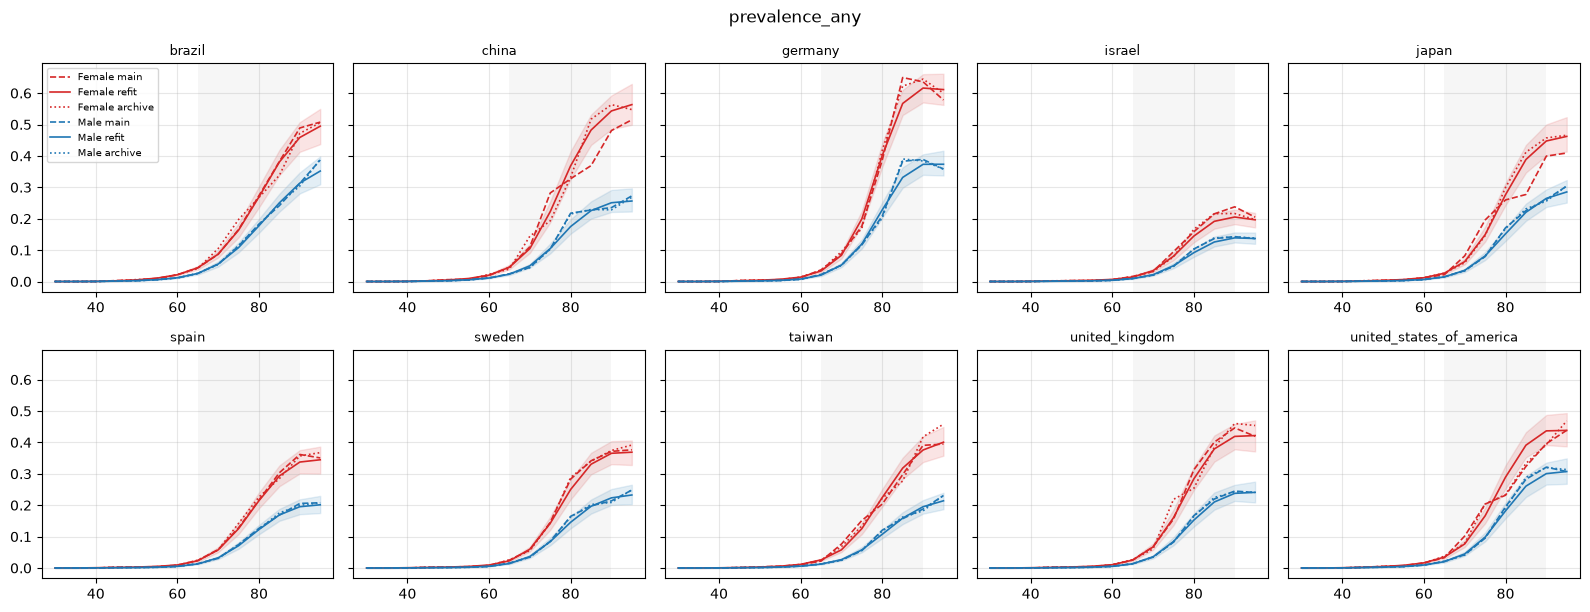

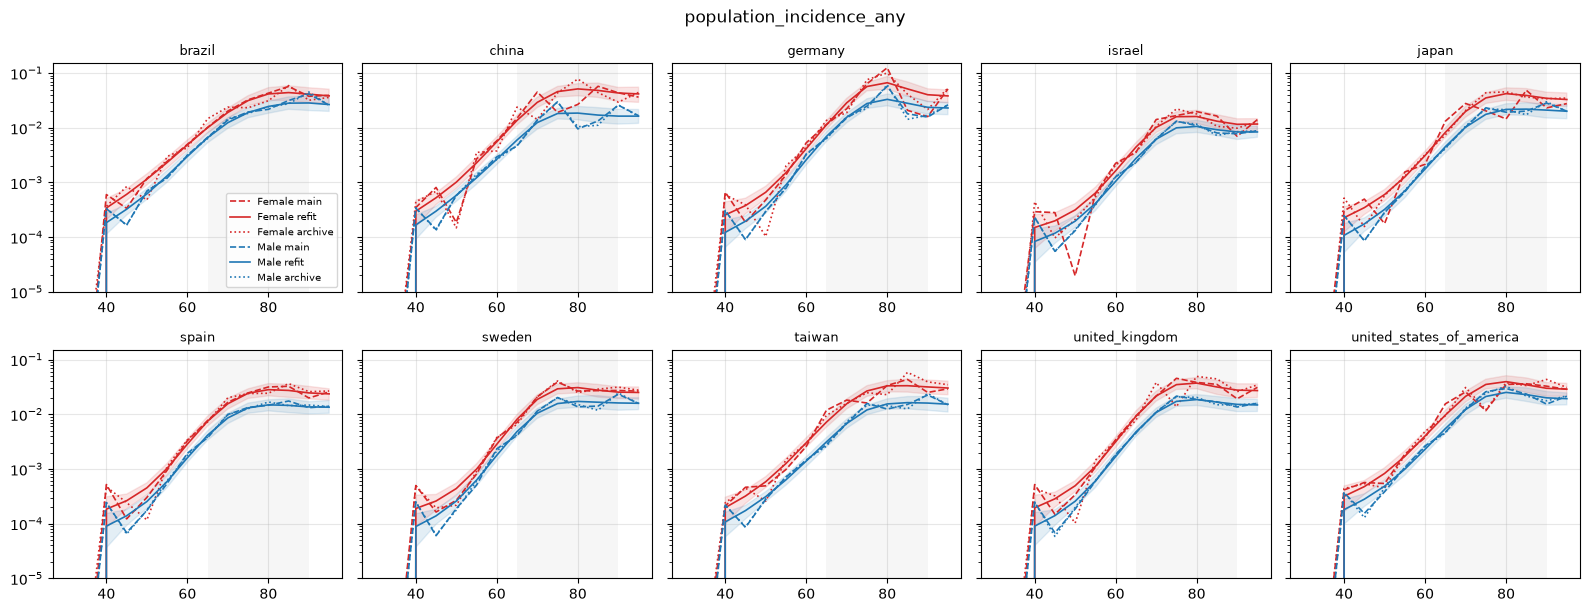

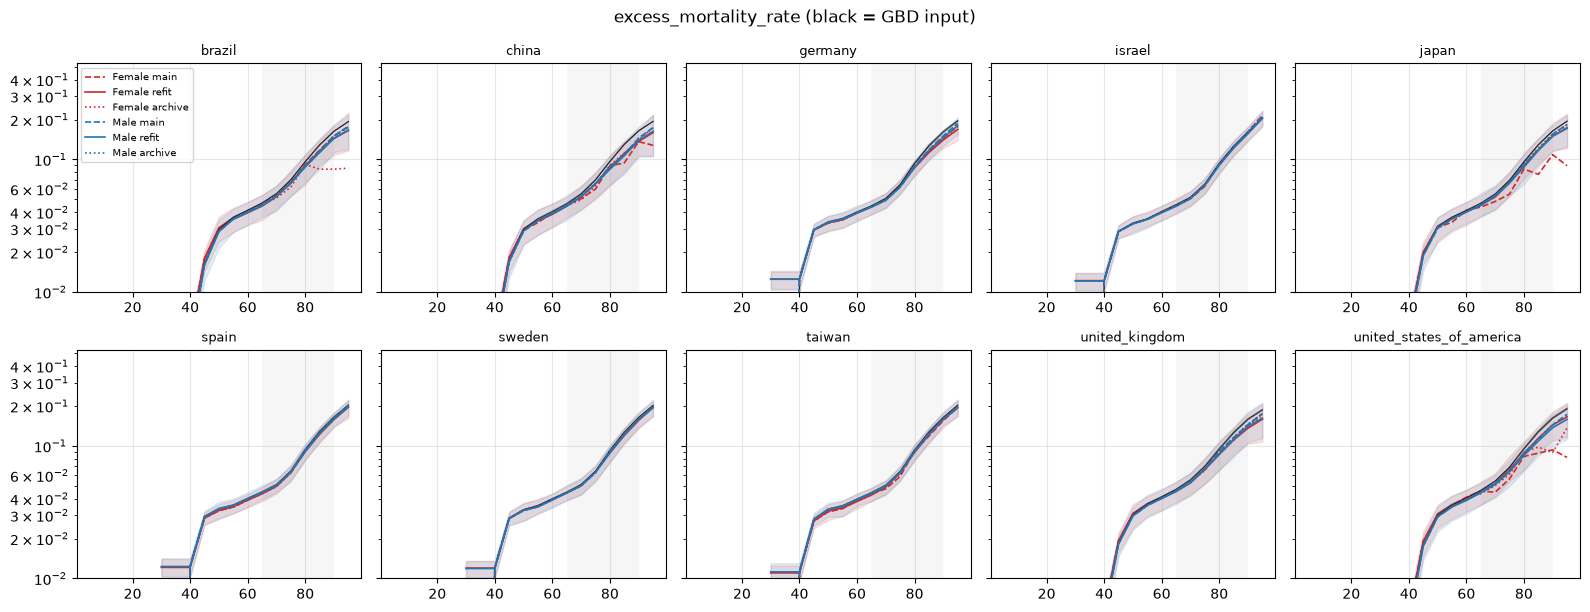

In [9]:
def grid(key, logy=False, gbd_key=None, ymin=None):
    n = len(LOCATIONS)
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(3.2 * ((n + 1) // 2), 6.2), sharey=True)
    for ax, loc in zip(axes.ravel(), LOCATIONS):
        for sex, color in [("Female", "C3"), ("Male", "C0")]:
            if gbd_key and "main" in arts[loc]:
                g = summarize(draws(arts[loc]["main"], gbd_key)).xs(sex)
                ax.plot(g.index, g["mean"], color="k", lw=0.8, alpha=0.6)
            for label, art in arts[loc].items():
                if key not in art.keys:
                    continue
                s = summarize(draws(art, key)).xs(sex)
                ax.plot(s.index, s["mean"], color=color, ls=STYLE[label]["ls"], lw=1.2,
                        label=f"{sex} {label}" if loc == LOCATIONS[0] else None)
                if label == "refit":
                    ax.fill_between(s.index, s.lo, s.hi, color=color, alpha=0.12)
        ax.set_title(loc, fontsize=9); ax.grid(alpha=0.3)
        ax.axvspan(*AGES_OF_INTEREST, color="grey", alpha=0.07, lw=0)
        if logy:
            ax.set_yscale("log")
        if ymin is not None:
            ax.set_ylim(bottom=ymin)
    for ax in axes.ravel()[len(LOCATIONS):]:
        ax.axis("off")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(short(key) + (" (black = GBD input)" if gbd_key else ""))
    fig.tight_layout()
    return fig

grid("cause.alzheimers_consistent.prevalence_any");
grid("cause.alzheimers_consistent.population_incidence_any", logy=True, ymin=1e-5);
grid("cause.alzheimers_consistent.excess_mortality_rate", logy=True, gbd_key="cause.alzheimers.excess_mortality_rate", ymin=1e-2);

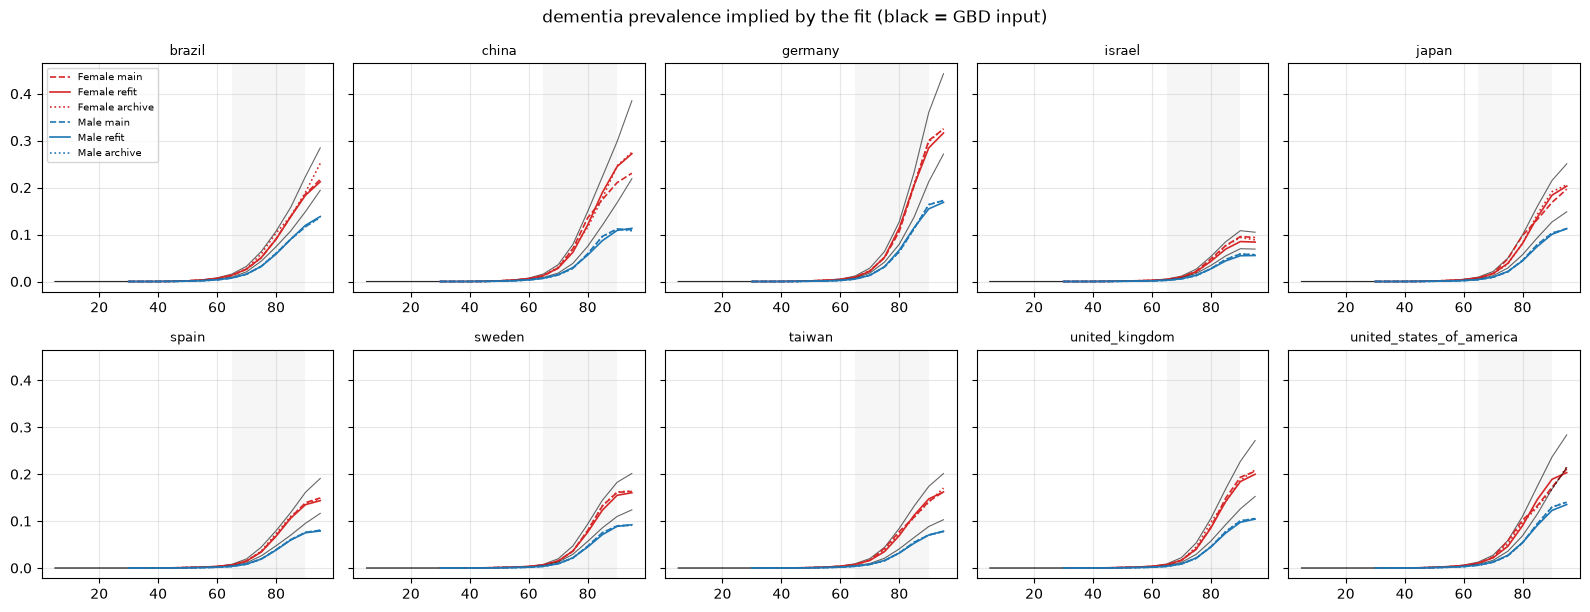

In [10]:
# Dementia prevalence implied by the fit (prevalence_any × dementia share) against the GBD input
n = len(LOCATIONS)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(3.2 * ((n + 1) // 2), 6.2), sharey=True)
for ax, loc in zip(axes.ravel(), LOCATIONS):
    for sex, color in [("Female", "C3"), ("Male", "C0")]:
        g = summarize(draws(arts[loc]["main"], "cause.alzheimers.prevalence")).xs(sex)
        ax.plot(g.index, g["mean"], color="k", lw=0.8, alpha=0.6)
        for label, art in arts[loc].items():
            dem = draws(art, "cause.alzheimers_consistent.prevalence_any") * draws(art, "cause.alzheimers_consistent.dementia_conditional_prevalence")
            s = summarize(dem).xs(sex)
            ax.plot(s.index, s["mean"], color=color, ls=STYLE[label]["ls"], lw=1.2,
                    label=f"{sex} {label}" if loc == LOCATIONS[0] else None)
    ax.set_title(loc, fontsize=9); ax.grid(alpha=0.3); ax.axvspan(*AGES_OF_INTEREST, color="grey", alpha=0.07, lw=0)
for ax in axes.ravel()[len(LOCATIONS):]:
    ax.axis("off")
axes[0, 0].legend(fontsize=7)
fig.suptitle("dementia prevalence implied by the fit (black = GBD input)"); fig.tight_layout()

## 5. New BBBM entrants per year

`susceptible_to_bbbm_transition_count` summed over ages (mean of draws), which with the
population size sets how many simulants enter each year.

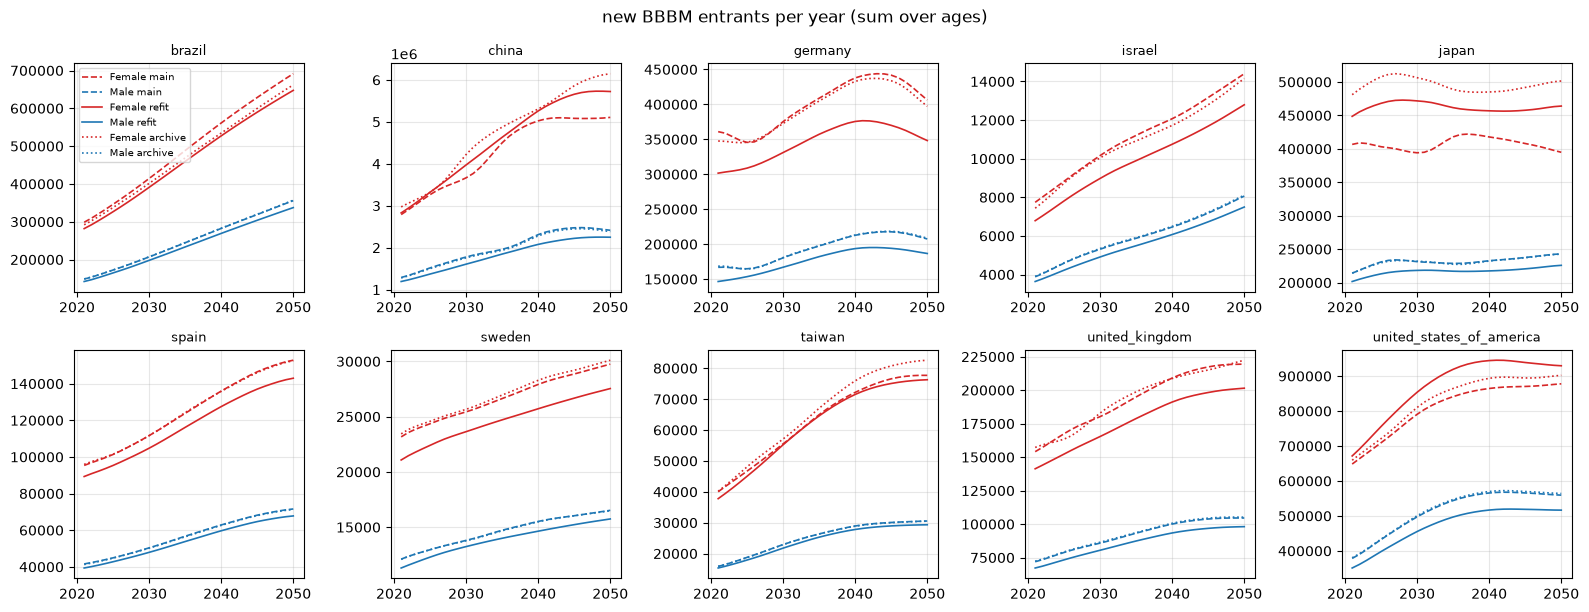

In [11]:
n = len(LOCATIONS)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(3.2 * ((n + 1) // 2), 6.2))
for ax, loc in zip(axes.ravel(), LOCATIONS):
    for label, art in arts[loc].items():
        tc = art.load("cause.alzheimers_consistent.susceptible_to_bbbm_transition_count")
        tc = tc[[c for c in tc.columns if str(c).startswith("draw_")]].mean(axis=1).groupby(["sex", "year_start"]).sum()
        for sex, color in [("Female", "C3"), ("Male", "C0")]:
            s = tc.xs(sex)
            ax.plot(s.index, s.values, color=color, ls=STYLE[label]["ls"], lw=1.2,
                    label=f"{sex} {label}" if loc == LOCATIONS[0] else None)
    ax.set_title(loc, fontsize=9); ax.grid(alpha=0.3)
for ax in axes.ravel()[len(LOCATIONS):]:
    ax.axis("off")
axes[0, 0].legend(fontsize=7)
fig.suptitle("new BBBM entrants per year (sum over ages)"); fig.tight_layout()

## Take-aways (written 2026-10-26)

- **Every location passed the gate at the first attempt.** All 20 fits ran at 63–85
  leapfrog steps per iteration with no divergent transitions; the worst r_hat is 1.011
  (UK Male) and the smallest ESS is 440 of 5,000 (Spain Female); 13–17 minutes per sex on
  one core, 4.9 core-hours in all. The weakest knot is always the BBBM share at age 40, the
  boundary knot the data pin least.
- **Main's draws are consecutive MCMC iterations** (lag-1 autocorrelation 0.62–0.89); the
  refit's are near-independent (−0.04 to 0.04), so `input_draw_number` picks genuinely
  different posterior samples.
- **Where main's one chain was stuck, the rates move.** Refit vs main at ages 65–90, Female:
  any-AD prevalence differs by 1–23% (Japan 23, USA 19, Taiwan 15, China 14) and the S→BBBM
  hazard by 7–70% (Japan 70, China 58, USA 55, Germany 47). Male differences are smaller
  except for the hazard. Averaged over keys and sexes, refit vs main is 2–14% per location,
  the same size as main vs archive (2–13%), which is the old sampler's own run-to-run noise
  plus nine months of input drift. The refit sits 4–12% from the archive.
- **The S→BBBM hazard is now a smooth function of age** in every location. The zigzag
  between adjacent knots that main and the archive show (China 45–55, Israel 50, USA 70–80)
  is gone, and its posterior band is several times narrower.
- **Unchanged:** every fit, old or new, sits below the GBD dementia prevalence above age 80.
  That is a property of the model, not of the sampler.